# Flux domicile-travail par station (matin vs soir) + carte

**Objectif** : identifier les stations qui se vident le matin (zones
d'emploi : les gens y prennent un vélo pour aller travailler) et celles qui
se remplissent le soir (zones résidentielles : les gens y ramènent le
vélo en rentrant).

**Méthode** : pour chaque station, moyenne des vélos disponibles sur la
fenêtre 7h-9h (matin) et 17h-19h (soir), jours de semaine uniquement
(vue `v_station_flux_domicile_travail`). `flux_net = soir - matin` :
positif ⇒ la station se remplit le soir (résidentiel) ; négatif ⇒ elle se
vide le matin (zone d'emploi).


In [1]:
%matplotlib inline
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import pandas as pd
from _common import get_engine

engine = get_engine()
df = pd.read_sql("SELECT * FROM v_station_flux_domicile_travail", engine)
df["flux_net"] = df["avg_velos_soir"] - df["avg_velos_matin"]
nb_matin = df["avg_velos_matin"].notna().sum()
nb_soir = df["avg_velos_soir"].notna().sum()
print(f"Stations avec une moyenne du matin calculable : {nb_matin} / {len(df)}")
print(f"Stations avec une moyenne du soir calculable   : {nb_soir} / {len(df)}")

Stations avec une moyenne du matin calculable : 1522 / 1522
Stations avec une moyenne du soir calculable   : 1522 / 1522


## Carte des stations


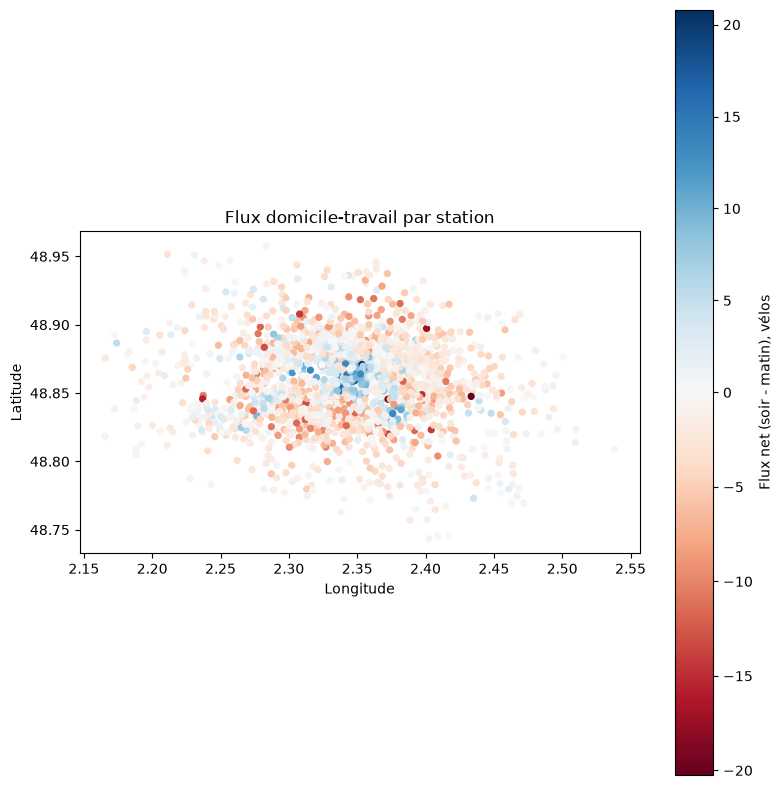

In [2]:
fig, ax = plt.subplots(figsize=(8, 8))

if df["flux_net"].notna().any():
    norm = mcolors.TwoSlopeNorm(vcenter=0)
    scatter = ax.scatter(df["lon"], df["lat"], c=df["flux_net"], cmap="RdBu", norm=norm, s=18)
    fig.colorbar(scatter, ax=ax, label="Flux net (soir - matin), vélos")
    titre = "Flux domicile-travail par station"
else:
    scatter = ax.scatter(df["lon"], df["lat"], c=df["avg_velos_soir"], cmap="viridis", s=18)
    fig.colorbar(scatter, ax=ax, label="Vélos disponibles en moyenne (17h-19h)")
    titre = "Disponibilité moyenne du soir\n(flux non calculable : pas de données du matin)"

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(titre)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Conclusion

Avec un mois de données, le flux domicile-travail est maintenant
calculable pour 1520/1522 stations, et le résultat est cohérent avec la
géographie réelle de Paris :

- **Flux positif le plus fort** (la station se remplit le soir) : des
  stations du centre de Paris (1er, 10e, 6e, 11e arrondissements) comme
  *Saint-Denis - Rivoli* (+22,3 vélos) ou *Quatre Vents - Carrefour de
  l'Odéon* (+18,5) — zones de bureaux, commerces et sorties où les gens
  arrivent à vélo en fin de journée.
- **Flux négatif le plus fort** (la station se vide le matin) : en tête,
  deux **gares** — *Gare RER de Vincennes* (-19,3) et *Gare de Lyon -
  Place Louis Armand* (-19,3) — exactement le comportement attendu : les
  usagers arrivent en train le matin puis prennent un vélo pour continuer
  leur trajet, et inversement le soir.

La carte ci-dessus confirme visuellement ce contraste centre (flux
positif, bleu) / gares et périphérie d'affaires (flux négatif, rouge).
C'est un signal géographique fort, directement exploitable comme feature
pour le modèle (position par rapport aux pôles d'emploi/gares).
